In [2]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

The PAN Personality Dataset is a multilingual personality prediction dataset released as part of the PAN Author Profiling tasks. It contains social media texts such as tweets and online posts collected from users in different languages including English and Spanish. Each text sample is labeled with personality traits or personality classes, making it suitable for Natural Language Processing (NLP) and machine learning tasks. The dataset is widely used for author profiling, personality detection, and behavioral text analysis research.

The dataset is widely used for tasks such as:

Personality prediction
Author profiling
Sentiment and behavioral analysis
Text classification
Multilingual NLP research

In [3]:
# Load dataset
df = pd.read_csv("spanish_dataset.csv")

In [4]:
# Show first 5 rows
print(df.head())

                                 userid  \
0  00370539-d641-4896-9398-5c8ecadf4284   
1  02d53a28-c464-49a2-93a6-42f408b0204c   
2  03080398-0a64-4f1f-8989-65bc84bd4631   
3  042c339f-fcc6-497d-923e-2e7dc3b4da44   
4  10f7ca83-cb58-46a3-a045-53e22f35b929   

                                                text      label  
0  Quiero esto http://t.co/spfh2RyIcQ\t\t Mi pelo...  extrovert  
1  @username buff doncs "m'alegra" saber que no s...  introvert  
2  Esto es progreso http://t.co/tc6Ljqe9eO\t\t "Y...  introvert  
3  1a prueba con la @username como media center c...  extrovert  
4  El mejor día:\nHOY\nEl peor error:\nNO PERSEVE...  introvert  


In [5]:
# Input and output
X = df["text"]
y = df["label"]

In [6]:
from nltk.corpus import stopwords
import nltk

nltk.download('stopwords')

spanish_stopwords = stopwords.words('spanish')

vectorizer = TfidfVectorizer(stop_words=spanish_stopwords)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Manoj\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
vectorizer = TfidfVectorizer()

# Convert text into numerical vectors
X_vectorized = vectorizer.fit_transform(X)

In [8]:
print(len(vectorizer.vocabulary_))

22549


In [9]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_vectorized,
    y,
    test_size=0.2,
    random_state=42
)

KNN Accuracy: 0.8333333333333334
              precision    recall  f1-score   support

   extrovert       0.00      0.00      0.00         1
   introvert       0.94      0.88      0.91        17

    accuracy                           0.83        18
   macro avg       0.47      0.44      0.45        18
weighted avg       0.89      0.83      0.86        18



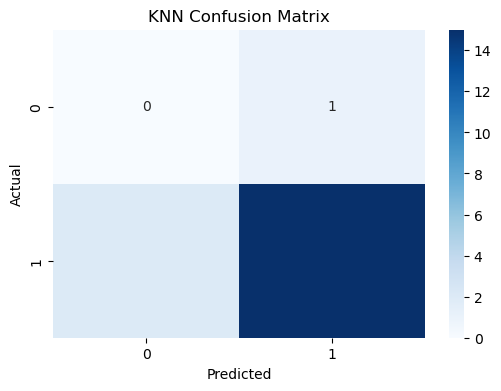

In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train
knn_model.fit(X_train, y_train)

# Predict
knn_pred = knn_model.predict(X_test)

# Accuracy
knn_acc = accuracy_score(y_test, knn_pred)

print("KNN Accuracy:", knn_acc)

# Classification Report
print(classification_report(y_test, knn_pred))

# Confusion Matrix
cm_knn = confusion_matrix(y_test, knn_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues')
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

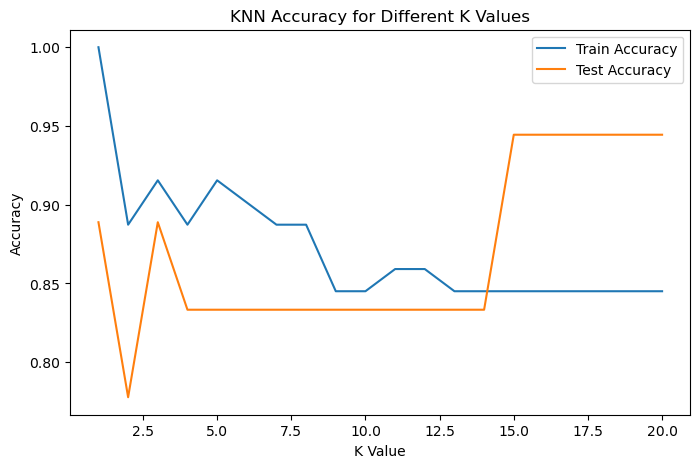

In [11]:
k_values = range(1, 21)
train_acc = []
test_acc = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train, y_train)

    train_acc.append(model.score(X_train, y_train))
    test_acc.append(model.score(X_test, y_test))

plt.figure(figsize=(8,5))

plt.plot(k_values, train_acc, label='Train Accuracy')
plt.plot(k_values, test_acc, label='Test Accuracy')

plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for Different K Values")

plt.legend()
plt.show()

Logistic Regression Accuracy: 0.9444444444444444
              precision    recall  f1-score   support

   extrovert       0.00      0.00      0.00         1
   introvert       0.94      1.00      0.97        17

    accuracy                           0.94        18
   macro avg       0.47      0.50      0.49        18
weighted avg       0.89      0.94      0.92        18



c:\Users\Manoj\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Manoj\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Manoj\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


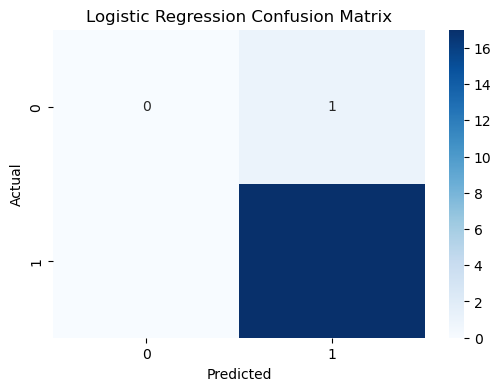

In [12]:
from sklearn.linear_model import LogisticRegression

# Model
lr_model = LogisticRegression(max_iter=1000)

# Train
lr_model.fit(X_train, y_train)

# Predict
lr_pred = lr_model.predict(X_test)

# Accuracy
lr_acc = accuracy_score(y_test, lr_pred)

print("Logistic Regression Accuracy:", lr_acc)

# Classification Report
print(classification_report(y_test, lr_pred))

# Confusion Matrix
cm_lr = confusion_matrix(y_test, lr_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues')
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

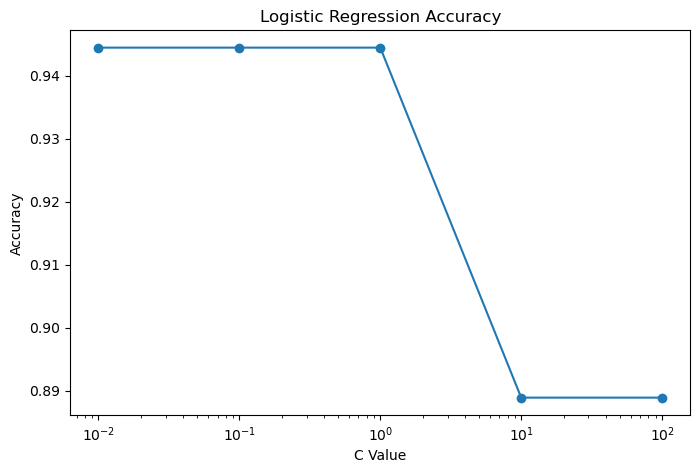

In [13]:
c_values = [0.01, 0.1, 1, 10, 100]
lr_scores = []

for c in c_values:

    model = LogisticRegression(
        C=c,
        max_iter=1000
    )

    model.fit(X_train, y_train)

    score = model.score(X_test, y_test)

    lr_scores.append(score)

plt.figure(figsize=(8,5))

plt.plot(c_values, lr_scores, marker='o')

plt.xscale('log')

plt.xlabel("C Value")
plt.ylabel("Accuracy")

plt.title("Logistic Regression Accuracy")

plt.show()

Random Forest Accuracy: 0.9444444444444444
              precision    recall  f1-score   support

   extrovert       0.00      0.00      0.00         1
   introvert       0.94      1.00      0.97        17

    accuracy                           0.94        18
   macro avg       0.47      0.50      0.49        18
weighted avg       0.89      0.94      0.92        18



c:\Users\Manoj\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Manoj\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Manoj\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


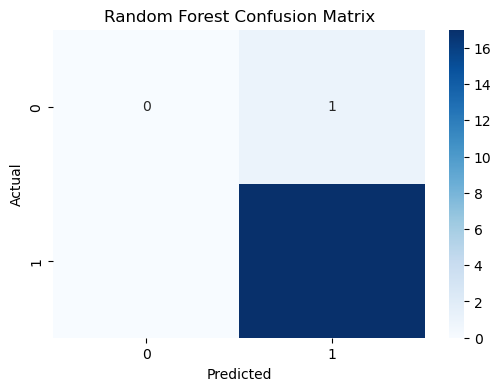

In [14]:
from sklearn.ensemble import RandomForestClassifier

# Model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train
rf_model.fit(X_train, y_train)

# Predict
rf_pred = rf_model.predict(X_test)

# Accuracy
rf_acc = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_acc)

# Classification Report
print(classification_report(y_test, rf_pred))

# Confusion Matrix
cm_rf = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues')
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

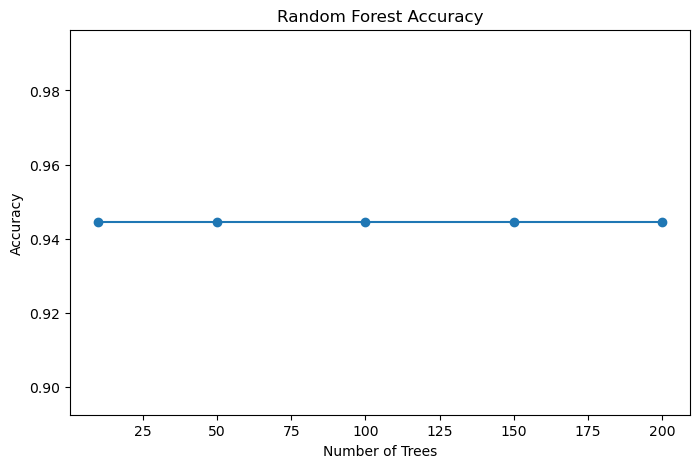

In [15]:
tree_values = [10, 50, 100, 150, 200]
rf_scores = []

for trees in tree_values:

    model = RandomForestClassifier(
        n_estimators=trees,
        random_state=42
    )

    model.fit(X_train, y_train)

    score = model.score(X_test, y_test)

    rf_scores.append(score)

plt.figure(figsize=(8,5))

plt.plot(tree_values, rf_scores, marker='o')

plt.xlabel("Number of Trees")
plt.ylabel("Accuracy")

plt.title("Random Forest Accuracy")

plt.show()

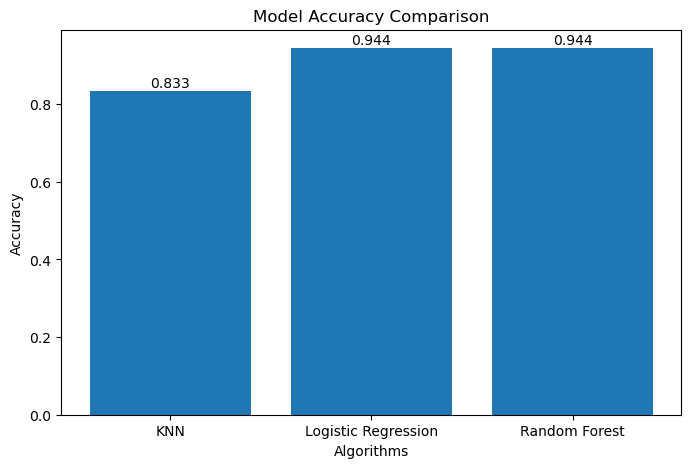

In [16]:
models = [
    'KNN',
    'Logistic Regression',
    'Random Forest'
]

accuracies = [
    knn_acc,
    lr_acc,
    rf_acc
]

plt.figure(figsize=(8,5))

bars = plt.bar(models, accuracies)

plt.xlabel("Algorithms")
plt.ylabel("Accuracy")

plt.title("Model Accuracy Comparison")

for bar in bars:

    yval = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 0.01,
        round(yval, 3),
        ha='center'
    )

plt.show()

In [17]:
# Custom input text in Spanish
custom_text = [
    "Me gusta conocer nuevas personas y salir a fiestas todos los fines de semana"
]

# Convert text to TF-IDF
custom_vector = vectorizer.transform(custom_text)

# Predict personality
prediction = model.predict(custom_vector)

print("\nPredicted Personality:", prediction[0])


Predicted Personality: introvert
